# Lab 7 — Go-to-goal: "47"

The robot drives the waypoints of "47" with the go-to-goal controller (`go_to_goal_sim.qrs` = `go_to_goal_real.qrs`, only the log name differs) and logs `theta_l, theta_r, time`. The trajectory is rebuilt here and compared with the ideal one.

| Setting | Value |
|---|---|
| $K_v$, $K_\theta$ | 1.5 1/s, 4.0 1/s |
| ε (acceptance radius) | 3 cm |
| $v_{max}$ | 0.15 m/s |
| $r$, $B$ | 0.042 m, 0.194 m |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

r, B = 0.042, 0.194
X_ref = np.array([0.0, 0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.8, 0.8])
Y_ref = np.array([0.0, -0.3, -0.3, 0.0, -0.6, 0.0, 0.0, 0.0, -0.6])
COURSE_0 = 0.0          # the robot starts at the first waypoint facing +x
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

## Step 1 — Reconstruct the trajectory

In [2]:
def reconstruct(name):
    theta_l, theta_r, t = np.loadtxt(name, delimiter=",", unpack=True)
    path = (theta_r + theta_l) * r / 2
    course = COURSE_0 + (theta_r - theta_l) * r / B
    x = np.zeros_like(path); y = np.zeros_like(path)
    x[0], y[0] = X_ref[0], Y_ref[0]
    for k in range(1, len(path)):
        x[k] = x[k - 1] + (path[k] - path[k - 1]) * np.cos(course[k])
        y[k] = y[k - 1] + (path[k] - path[k - 1]) * np.sin(course[k])
    return dict(t=(t - t[0]) / 1000, x=x, y=y, course=course)

runs = {}
for label, f in (("sim", "odometry_data_sim.txt"), ("real", "odometry_data_real.txt")):
    if os.path.exists(f):
        runs[label] = reconstruct(f)
        print(f"{label}: {len(runs[label]['t'])} samples, {runs[label]['t'][-1]:.1f} s")
    else:
        print(f"{label}: {f} not recorded yet")

sim: 2683 samples, 26.8 s
real: 217 samples, 21.8 s


## Steps 2–4 — Ideal segments, `distance` and `courseAngle`

Each sample is assigned to the nearest segment, moving only to the next one. Where two segments lie on top of each other (the "4" goes up and down the same line), the one whose direction matches the robot's course wins.

In [3]:
course_ref = np.arctan2(np.diff(Y_ref), np.diff(X_ref))      # course_ref[i-1] for segment i
wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi

def seg_dist(px, py, i):
    ax, ay, bx, by = X_ref[i - 1], Y_ref[i - 1], X_ref[i], Y_ref[i]
    u = np.clip(((px - ax) * (bx - ax) + (py - ay) * (by - ay)) / ((bx - ax) ** 2 + (by - ay) ** 2), 0, 1)
    return np.hypot(px - ax - u * (bx - ax), py - ay - u * (by - ay))

def errors(run):
    seg = np.ones(len(run["t"]), dtype=int); i = 1
    for k in range(len(seg)):
        if i < len(X_ref) - 1:
            d_now, d_next = seg_dist(run["x"][k], run["y"][k], i), seg_dist(run["x"][k], run["y"][k], i + 1)
            closer = abs(wrap(course_ref[i] - run["course"][k])) < abs(wrap(course_ref[i - 1] - run["course"][k]))
            if d_next < d_now - 0.005 or (abs(d_next - d_now) <= 0.005 and closer):
                i += 1
        seg[k] = i
    cr = course_ref[seg - 1]
    run["seg"] = seg
    run["distance"] = -(run["x"] - X_ref[seg - 1]) * np.sin(cr) + (run["y"] - Y_ref[seg - 1]) * np.cos(cr)
    run["courseAngle"] = np.degrees(wrap(cr - run["course"]))

for run in runs.values():
    errors(run)

## Step 5 — Plots and summary

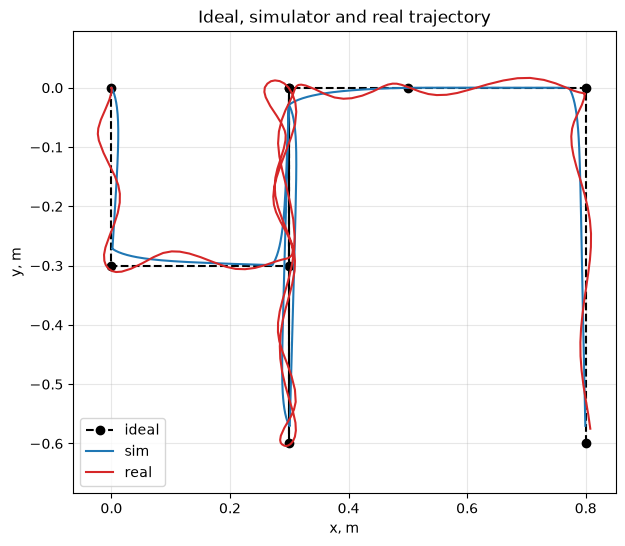

In [4]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(X_ref, Y_ref, "k--o", label="ideal")
for label, c in (("sim", "tab:blue"), ("real", "tab:red")):
    if label in runs:
        ax.plot(runs[label]["x"], runs[label]["y"], color=c, label=label)
ax.axis("equal"); ax.set_xlabel("x, m"); ax.set_ylabel("y, m"); ax.legend(); ax.set_title("Ideal, simulator and real trajectory")
plt.show()

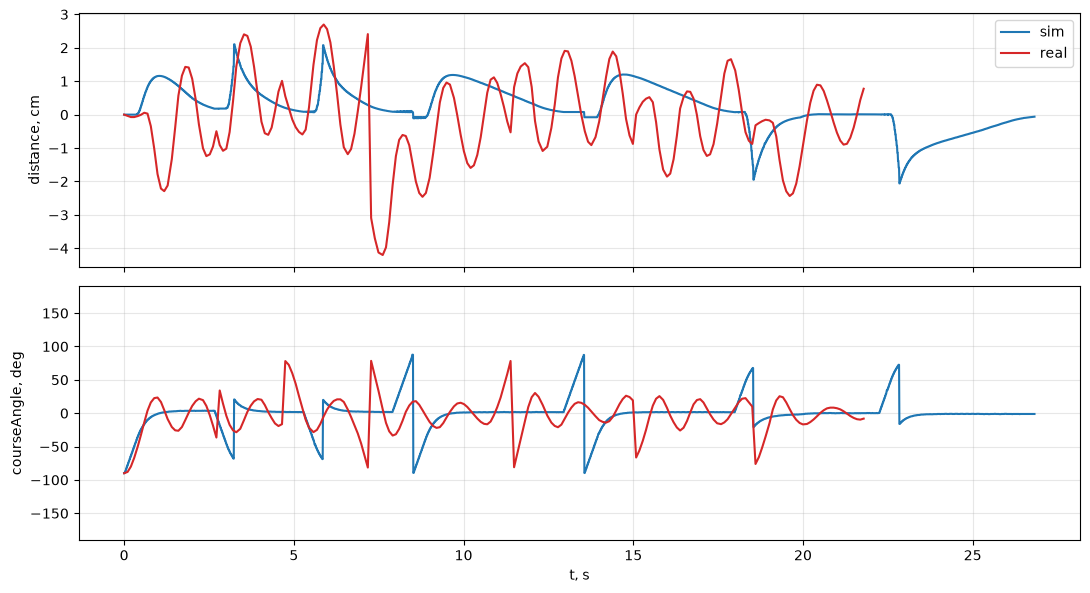

In [5]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for label, c in (("sim", "tab:blue"), ("real", "tab:red")):
    if label in runs:
        a1.plot(runs[label]["t"], 100 * runs[label]["distance"], color=c, label=label)
        a2.plot(runs[label]["t"], runs[label]["courseAngle"], color=c, label=label)
a1.set_ylabel("distance, cm"); a1.legend()
a2.set_ylabel("courseAngle, deg"); a2.set_xlabel("t, s"); a2.set_ylim(-190, 190)
plt.tight_layout(); plt.show()

`courseAngle` peaks at every corner while the robot turns; judge it on the straight parts.

In [6]:
miss = pd.DataFrame({"waypoint": [f"({X_ref[i]:.1f}, {Y_ref[i]:.1f})" for i in range(len(X_ref))]})
for label, run in runs.items():
    miss[f"{label} miss, cm"] = [100 * np.min(np.hypot(run["x"] - X_ref[i], run["y"] - Y_ref[i])) for i in range(len(X_ref))]
miss.round(1)

,waypoint,"sim miss, cm","real miss, cm"
0,"(0.0, 0.0)",0.0,0.0
1,"(0.0, -0.3)",2.6,0.7
2,"(0.3, -0.3)",0.8,0.6
3,"(0.3, 0.0)",2.5,0.1
4,"(0.3, -0.6)",2.9,0.2
5,"(0.3, 0.0)",2.5,0.1
6,"(0.5, 0.0)",0.1,0.4
7,"(0.8, 0.0)",2.5,1.0
8,"(0.8, -0.6)",3.0,2.6


In [7]:
def straight(run):
    # samples away from the corners: at least 5 cm from both ends of their segment
    a = np.hypot(run["x"] - X_ref[run["seg"] - 1], run["y"] - Y_ref[run["seg"] - 1])
    b = np.hypot(run["x"] - X_ref[run["seg"]], run["y"] - Y_ref[run["seg"]])
    return (a > 0.05) & (b > 0.05)

summary = pd.DataFrame({label: {
    "max |distance|, cm": 100 * np.max(np.abs(run["distance"])),
    "RMS distance, cm": 100 * np.sqrt(np.mean(run["distance"] ** 2)),
    "mean |courseAngle|, deg": np.mean(np.abs(run["courseAngle"])),
    "mean |courseAngle| on straights, deg": np.mean(np.abs(run["courseAngle"][straight(run)])),
    "final error to last waypoint, cm": 100 * np.hypot(run["x"][-1] - X_ref[-1], run["y"][-1] - Y_ref[-1]),
    "run time, s": run["t"][-1]} for label, run in runs.items()})
summary.round(2)

,sim,real
"max |distance|, cm",2.10,4.20
"RMS distance, cm",0.68,1.29
"mean |courseAngle|, deg",10.84,20.22
"mean |courseAngle| on straights, deg",2.15,12.81
"final error to last waypoint, cm",2.98,2.61
"run time, s",26.82,21.79


## Conclusions

* In the simulator the robot stays within 2.1 cm of the ideal "47". `distance` and `courseAngle` only jump at the corners, where the robot switches waypoints 3 cm early (ε), so every corner is cut by up to ε.
* On the real robot `distance` swings ±2 cm (max 4.2 cm) and `courseAngle` ±25° about once per second on every segment: the robot weaves. Cause: **K_θ = 4 is too high for the real robot**. Its loop runs every ≈ 100 ms instead of 10 ms (file writing), and its motors are ≈ 2.4× faster at the same power, so each heading correction overshoots.
* Waypoints are still reached within 2.6 cm, so the controller does its job; a lower K_θ (or a faster loop) would remove the weaving.
* The real `distance` and `courseAngle` come from the robot's own odometry, so the remaining real-vs-model gap is a **control** problem. A **localization** error (wheel slip, wrong r or B) cannot be seen here, because the end point was not measured with a tape.